In [1]:
import  warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, auc, mean_absolute_error, mean_squared_error, accuracy_score, confusion_matrix, roc_curve, calinski_harabasz_score
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

## Загрузка и описание датасета

## Описание датасета

Датасет инди-игр в Steam собран методом веб-скрейпинга, для каждой игры отправлялся отдельный запрос к Steam Store API, что позволило получить структурированные данные непосредственно из официального источника. Список игр для скрейпинга был
получен через SteamSpy API по тегу Indie, в этом жанре были отобраны наиболее популярные игры

Размерность датасета: 280 строк (игр) × 19 столбцов (признаков).

Датасет содержит как метрические, так и категориальные признаки и охватывает
информацию о ценах, оценках, популярности, жанрах и технических характеристиках
инди-игр, вышедших в период с 1997 по 2025 год.

In [3]:
df = pd.read_excel("../data/steam_indie_games.xlsx")
print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head(5)


Размерность датасета: 280 строк, 19 столбцов


,app_id,name,developer,publisher,release_year,is_free,price_usd,original_price_usd,discount_percent,required_age,metacritic_score,recommendations,achievements_count,dlc_count,platforms_count,has_single_player,has_multiplayer,has_co_op,genres
0,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",2017,1,0.00,0.00,0,13,0,1756391,37,0,1,0,1,0,"Action, Adventure, Massively Multiplayer, Free..."
1,1623730,Palworld,Pocketpair,Pocketpair,2024,0,22.49,29.99,25,0,0,349359,57,1,1,1,1,1,"Action, Adventure, Indie, RPG, Early Access"
2,304930,Unturned,Smartly Dressed Games,Smartly Dressed Games,2017,1,0.00,0.00,0,0,0,7531,88,1,3,1,1,1,"Action, Adventure, Casual, Indie, Free To Play"
3,105600,Terraria,Re-Logic,Re-Logic,2011,0,9.99,9.99,0,0,83,1193968,137,2,3,1,1,1,"Action, Adventure, Indie, RPG"
4,431960,Wallpaper Engine,Wallpaper Engine Team,Wallpaper Engine Team,2018,0,4.99,4.99,0,0,0,892269,17,1,1,0,0,0,"Casual, Indie, Animation & Modeling, Design & ..."


In [44]:
info = pd.DataFrame({
    'Тип данных':        df.dtypes,
    'Пустых значений':   df.isnull().sum(),
    'Уникальных':        df.nunique(),
    'Пример значения':   df.iloc[0],
})
info

,Тип данных,Пустых значений,Уникальных,Пример значения
app_id,int64,0,280,578080
name,object,0,280,PUBG: BATTLEGROUNDS
developer,object,0,250,PUBG Corporation
publisher,object,3,220,"KRAFTON, Inc."
release_year,int64,0,21,2017
is_free,int64,0,2,1
price_usd,float64,0,43,0.0
original_price_usd,float64,0,26,0.0
discount_percent,int64,0,17,0
required_age,int64,0,4,13


In [45]:
df.describe().round(2)


,app_id,release_year,is_free,price_usd,original_price_usd,discount_percent,required_age,metacritic_score,recommendations,achievements_count,dlc_count,platforms_count,has_single_player,has_multiplayer,has_co_op
count,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00,280.00
mean,563071.40,2016.85,0.21,12.44,14.52,10.67,1.13,42.25,104304.42,65.24,5.99,1.98,0.82,0.60,0.42
std,517106.35,3.94,0.41,11.78,12.51,25.55,4.22,40.64,199474.98,110.10,19.48,0.89,0.38,0.49,0.49
min,50.00,1997.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
25%,250317.50,2014.75,0.00,0.52,0.99,0.00,0.00,0.00,3648.75,16.00,0.00,1.00,1.00,0.00,0.00
50%,390555.00,2017.00,0.00,9.99,14.99,0.00,0.00,64.00,44287.50,36.00,1.00,2.00,1.00,1.00,0.00
75%,672400.00,2019.00,0.00,19.99,19.99,0.00,0.00,82.00,105039.00,68.25,5.00,3.00,1.00,1.00,1.00
max,3097560.00,2025.00,1.00,49.99,59.99,90.00,18.00,97.00,1756391.00,849.00,262.00,3.00,1.00,1.00,1.00


In [46]:
for col in ['is_free', 'has_single_player', 'has_multiplayer', 'has_co_op', 'platforms_count']:
    print(f"\n{col}:")
    print(df[col].value_counts())



is_free:
is_free
0    222
1     58
Name: count, dtype: int64

has_single_player:
has_single_player
1    230
0     50
Name: count, dtype: int64

has_multiplayer:
has_multiplayer
1    168
0    112
Name: count, dtype: int64

has_co_op:
has_co_op
0    162
1    118
Name: count, dtype: int64

platforms_count:
platforms_count
1    113
3    106
2     61
Name: count, dtype: int64



### Описание признаков

**`app_id`** - уникальный числовой идентификатор игры в базе данных Steam.
Не несёт аналитической ценности, используется как ключ для идентификации записи.
Тип: номинальный. Пустых значений: 0

**`name`** - название игры. Текстовый признак, используется для идентификации
и фильтрации. Тип: номинальный. Пустых значений: 0

**`developer`** - название компании или разработчика, создавшего игру. В датасете 250 уникальных разработчиков.
Тип: номинальный. Пустых значений: 0

**`publisher`** - название издателя игры. В ряде случаев совпадает с разработчиком. Тип: номинальный.
Пустых значений: **3**

**`release_year`** - год выпуска игры. Значения варьируются от 1997 до 2025,
основная масса игр выпущена после 2014 года.
Тип: метрический (дискретный). Пустых значений: 0

**`is_free`** - флаг бесплатности игры. Принимает значение 1, если игра бесплатна,
и 0, если требует покупки. В датасете 21% игр являются бесплатными.
Тип: бинарный. Пустых значений: 0

**`price_usd`** - текущая цена игры в долларах США (с учётом скидок).
Для бесплатных игр равна 0. Значения варьируются от 0 до 49.99, медиана - 9.99$.
Тип: метрический. Пустых значений: 0

**`original_price_usd`** - исходная цена игры без скидки в долларах США.
Используется для расчёта фактической экономии покупателя. Значения: от 0 до 59.99$.
Тип: метрический. Пустых значений: 0

**`discount_percent`** - величина текущей скидки в процентах. Значения варьируются
от 0% до 90%. Большинство игр в момент сбора данных продавались без скидки.
Тип: метрический (дискретный). Пустых значений: 0

**`required_age`** - возрастной рейтинг игры. Принимает значения 0,
13, 16 или 18. Отражает наличие контента для взрослых. Тип: порядковый.
Пустых значений: 0

**`metacritic_score`** - агрегированная оценка прессы на сайте Metacritic,
от 0 до 100. Значение 0 означает отсутствие оценки, большинство инди-игр её не имеют.
Тип: метрический (дискретный). Пустых значений: 0

**`recommendations`** - общее число пользовательских рекомендаций в Steam. Тип: метрический (дискретный). Пустых значений: 0

**`achievements_count`** - количество внутриигровых достижений.
Варьируется от 0 (достижений нет) до нескольких сотен. Косвенно отражает
глубину контента и вовлечённость игрока. Тип: метрический (дискретный).
Пустых значений: 0

**`dlc_count`** - количество дополнений, выпущенных для игры.
Отражает монетизационную стратегию разработчика и степень развития игры после релиза.
Тип: метрический (дискретный). Пустых значений: 0

**`platforms_count`** - количество поддерживаемых платформ: 1 (только Windows),
2 (Windows + Mac или Windows + Linux) или 3 (все платформы). В датасете: 113 игр
поддерживают только Windows, 61 - две платформы, 106 - все три.
Тип: порядковый. Пустых значений: 0

**`has_single_player`** - наличие одиночного режима игры. 1 - есть, 0 - нет.
Тип: бинарный. Пустых значений: 0

**`has_multiplayer`** - наличие онлайн-мультиплеера. 1 - есть, 0 - нет.
168 игр из 280 поддерживают мультиплеер. Тип: бинарный. Пустых значений: 0

**`has_co_op`** - наличие кооперативного режима (локального или онлайн).
1 - есть, 0 - нет. 118 игр поддерживают кооп. Тип: бинарный. Пустых значений: 0

**`genres`** - жанры игры в виде текстовой строки с перечислением через запятую
(например, «Action, Adventure, RPG»). Одна игра может относиться к нескольким жанрам.
Всего в датасете встречается 123 уникальных комбинации жанров.
Тип: номинальный. Пустых значений: 0


## Изменение типов данных

In [47]:
for col in ['is_free', 'has_single_player', 'has_multiplayer', 'has_co_op']:
    df[col] = df[col].astype(bool)

df.dtypes

app_id                  int64
name                   object
developer              object
publisher              object
release_year            int64
is_free                  bool
price_usd             float64
original_price_usd    float64
discount_percent        int64
required_age            int64
metacritic_score        int64
recommendations         int64
achievements_count      int64
dlc_count               int64
platforms_count         int64
has_single_player        bool
has_multiplayer          bool
has_co_op                bool
genres                 object
dtype: object

Поменяли типы данных для бинарных признаков на логические (bool), теперь признаки `is_free`, `has_single_player`, `has_multiplayer` и `has_co_op` принимают значения True/False вместо 1/0 для удобства анализа

## Новый столбец

In [48]:
df['discount_usd'] = (df['original_price_usd'] - df['price_usd']).clip(lower=0).round(2)

df[['name', 'price_usd', 'original_price_usd', 'discount_percent', 'discount_usd']].head(10)

,name,price_usd,original_price_usd,discount_percent,discount_usd
0,PUBG: BATTLEGROUNDS,0.00,0.00,0,0.0
1,Palworld,22.49,29.99,25,7.5
2,Unturned,0.00,0.00,0,0.0
3,Terraria,9.99,9.99,0,0.0
4,Wallpaper Engine,4.99,4.99,0,0.0
5,Brawlhalla,0.00,0.00,0,0.0
6,Garry's Mod,4.99,9.99,50,5.0
7,Rust,39.99,39.99,0,0.0
8,ARK: Survival Evolved,9.89,14.99,34,5.1
9,Stardew Valley,14.99,14.99,0,0.0


Был добавлен признак `discount_usd` - абсолютный размер скидки в долларах США.
Он рассчитывается как разница между `original_price_usd` (цена без скидки) и `price_usd` (текущая цена).
Если исходная цена меньше текущей, значение принудительно ограничивается снизу нулём.
Этот признак удобнее для анализа, чем `discount_percent`, потому что показывает реальную экономию покупателя в деньгах и позволяет сравнивать скидки между играми разных ценовых сегментов.


## Перекодирование метрического признака в категориальный

In [49]:
def categorize_price(row):
    if row['is_free'] or row['price_usd'] == 0:
        return 'Бесплатно'
    elif row['price_usd'] <= 5.0:
        return 'Бюджетная (<=5$)'
    elif row['price_usd'] <= 15.0:
        return 'Средняя (5–15$)'
    elif row['price_usd'] <= 30.0:
        return 'Премиум (15–30$)'
    else:
        return 'Дорогая (>30$)'

cat_order = ['Бесплатно', 'Бюджетная (<=5$)', 'Средняя (5–15$)', 'Премиум (15–30$)', 'Дорогая (>30$)']
df['price_category'] = pd.Categorical(
    df.apply(categorize_price, axis=1),
    categories=cat_order,
    ordered=True
)

df['price_category'].value_counts().sort_index()

price_category
Бесплатно           69
Бюджетная (<=5$)    45
Средняя (5–15$)     72
Премиум (15–30$)    80
Дорогая (>30$)      14
Name: count, dtype: int64

Выбраны следующие интервалы для категоризации цен:
- Бесплатно (0\$) - игры с моделью Free-to-Play, которые монетизируются через внутриигровые покупки или рекламу, а не через прямую продажу.
- Бюджетная (до 5\$) - игры, которые часто покупаются импульсивно, их цена не является серьёзным барьером для большинства игроков.
- Средняя (5–15\$) - стандартный и самый массовый ценовой диапазон для большинства инди-игр на платформе.
- Премиум (15–30\$) - высокобюджетные инди-игры (AA-уровень) или крупные хиты в раннем доступе, которые предлагают более глубокий и качественный контент.
- Дорогая (более 30\$) - нетипично высокая цена для инди-сегмента, сопоставимая с крупными коммерческими проектами (AAA).

Тип нового признака - категориальный, что в дальнейшем позволит корректно отображать его на графиках и учитывать внутреннюю иерархию цен


## Цель и задачи исследования

**Цель исследования:**
Выявить ключевые факторы, определяющие коммерческую популярность и ценообразование инди-игр в магазине Steam. Основной акцент делается на поиске взаимосвязей между объективными характеристиками продукта (жанр, цена, технические возможности) и его рыночным успехом, выраженным в количестве пользовательских рекомендаций.

**Задачи исследования:**
1. Анализ структуры рынка: Описать текущее состояние рынка инди-игр, исследовав распределение проектов по ценовым сегментам, жанрам и годам выпуска.
2. Исследование ценовых стратегий: Изучить взаимосвязь между ценой игры (включая скидки и free-to-play модель) и её популярностью, чтобы понять, насколько чувствительна аудитория к стоимости инди-продуктов.
3. Оценка влияния качества (Metacritic): Проверить гипотезу о корреляции между профессиональными оценками критиков и массовым признанием игроков (количеством рекомендаций).
4. Анализ функциональных характеристик: Оценить вклад дополнительных функций (онлайн-мультиплеер, кооператив, достижения, DLC) в коммерческий успех игры.
5. Роль технической доступности: Проверить, влияет ли поддержка альтернативных платформ (macOS, Linux) на расширение аудитории и рост популярности.
6. Предиктивное моделирование: Построить регрессионные модели для предсказания популярности игры на основе совокупности её характеристик.
7. Сегментация игр: Провести кластерный анализ для выделения типовых групп инди-игр (например, «хиты», «нишевые проекты», «массовка») и описать их ключевые особенности.
8. Формирование рекомендаций: На основе полученных данных сформулировать практические советы для инди-разработчиков по оптимизации характеристик игры для повышения шансов на успех в Steam.


## 7. Исследовательские гипотезы

**1. Гипотеза о связи между оценкой критиков и популярностью у игроков**
* **$H_0$:** Линейная корреляция между оценкой на Metacritic и логарифмом числа пользовательских рекомендаций равна нулю.
* **$H_1$:** Существует статистически значимая положительная линейная корреляция между этими признаками.
* **Признаки:** `metacritic_score` (метрический), `log_recommendations` (логарифмированный метрический).
* **Метод:** Коэффициент корреляции Пирсона.

**2. Гипотеза о взаимосвязи цены и оценки критиков**
* **$H_0$:** Между ценой игры и её оценкой на Metacritic нет монотонной статистической взаимосвязи.
* **$H_1$:** Существует значимая положительная монотонная взаимосвязь (чем дороже игра, тем выше оценка).
* **Признаки:** `price_usd` (метрический), `metacritic_score` (метрический).
* **Метод:** Коэффициент ранговой корреляции Спирмена (так как распределение цен скошено вправо и может присутствовать нелинейность).

**3. Гипотеза о связи между количеством внутриигровых достижений и популярностью**
* **$H_0$:** Между количеством достижений и количеством рекомендаций нет монотонной взаимосвязи.
* **$H_1$:** Существует статистически значимая монотонная взаимосвязь между количеством достижений и числом рекомендаций.
* **Признаки:** `achievements_count` (метрический), `recommendations` (метрический).
* **Метод:** Коэффициент ранговой корреляции Спирмена.

**4. Гипотеза о взаимосвязи возраста игры и количества рекомендаций**
* **$H_0$:** Год выпуска игры и логарифм количества накопленных рекомендаций линейно независимы.
* **$H_1$:** Существует статистически значимая отрицательная линейная корреляция (чем старше игра, тем больше отзывов).
* **Признаки:** `release_year` (метрический), `log_recommendations` (метрический).
* **Метод:** Коэффициент корреляции Пирсона.

**5. Гипотеза о связи размера скидки (в долларах) и популярности**
* **$H_0$:** Абсолютный размер скидки не имеет монотонной связи с количеством рекомендаций.
* **$H_1$:** Существует положительная монотонная связь между абсолютным размером скидки и количеством рекомендаций.
* **Признаки:** `discount_usd` (метрический), `recommendations` (метрический).
* **Метод:** Коэффициент ранговой корреляции Спирмена.

**6. Гипотеза о различии популярности игр с мультиплеером и без него**
* **$H_0$:** Средние значения логарифма количества рекомендаций для игр с мультиплеером и одиночных игр равны.
* **$H_1$:** Среднее значение логарифма рекомендаций для игр с мультиплеером значимо выше.
* **Признаки:** `has_multiplayer` (бинарный), `log_recommendations` (метрический).
* **Метод:** Двухвыборочный T-тест независимых выборок (применяется к логарифмированным данным для приближения распределения к нормальному).

**7. Гипотеза о различии популярности платных и бесплатных игр**
* **$H_0$:** Средние значения логарифма количества рекомендаций для платных и бесплатных игр равны.
* **$H_1$:** Бесплатные игры имеют статистически значимо большее среднее количество рекомендаций (в логарифмической шкале).
* **Признаки:** `is_free` (бинарный), `log_recommendations` (метрический).
* **Метод:** Двухвыборочный T-тест независимых выборок.

**8. Гипотеза о связи между ценовой категорией игры и количеством поддерживаемых платформ**
* **$H_0$:** Ценовая категория игры и количество поддерживаемых ею платформ являются статистически независимыми признаками.
* **$H_1$:** Между ценовой категорией и числом поддерживаемых платформ существует статистически значимая взаимосвязь.
* **Признаки:** `price_category` (категориальный), `platforms_count` (категориальный).
* **Метод:** Тест Хи-квадрат Пирсона (анализ таблицы сопряженности).

**9. Гипотеза о взаимосвязи наличия кооперативного режима и мультиплеера**
* **$H_0$:** Наличие кооперативного режима и наличие мультиплеера независимы друг от друга.
* **$H_1$:** Между наличием кооперативного режима и мультиплеером есть статистически значимая взаимосвязь (совместная встречаемость).
* **Признаки:** `has_co_op` (бинарный), `has_multiplayer` (бинарный).
* **Метод:** Тест Хи-квадрат Пирсона.

**10. Гипотеза о связи бесплатной модели распространения и наличия мультиплеера**
* **$H_0$:** Бесплатная модель распространения игры (F2P) и наличие в ней мультиплеера независимы.
* **$H_1$:** Существует статистически значимая зависимость между тем, бесплатна ли игра, и наличием в ней мультиплеера.
* **Признаки:** `is_free` (бинарный), `has_multiplayer` (бинарный).
* **Метод:** Тест Хи-квадрат Пирсона.


## Графики

In [50]:
df['log_recommendations'] = np.log1p(df['recommendations'])

#### Распределение оценок критиков для платных и бесплатных игр

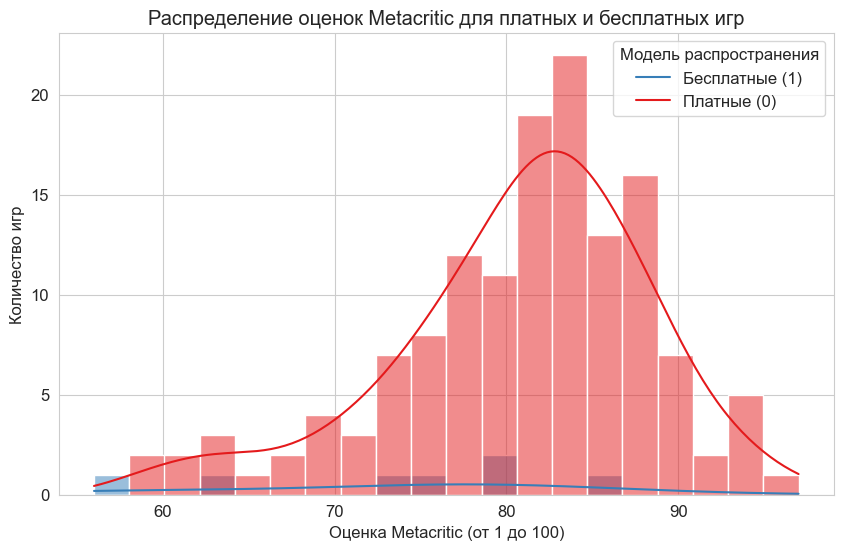

In [51]:
plt.figure(figsize=(10, 6))

# Оставляем только те игры, у которых есть оценка Metacritic (score > 0)
sns.histplot(data=df[df['metacritic_score'] > 0],
             x='metacritic_score',
             hue='is_free',
             kde=True,
             bins=20,
             palette='Set1')

plt.title('Распределение оценок Metacritic для платных и бесплатных игр')
plt.xlabel('Оценка Metacritic (от 1 до 100)')
plt.ylabel('Количество игр')

# Настройка легенды
plt.legend(title='Модель распространения', labels=['Бесплатные (1)', 'Платные (0)'])
plt.show()

На графике представлено распределение оценок критиков для платных и бесплатных проектов. По результатам визуализации можно выявить следующие тенденции:

Доминирование платных проектов в обзорах прессы: Подавляющее большинство игр, получивших оценку на Metacritic, являются платными (красные столбцы и линия). Бесплатных игр с рейтингом в выборке крайне мало (плоская синяя линия у основания). Это указывает на то, что профессиональные критики фокусируются на коммерческих релизах и редко делают обзоры на бесплатные проекты.

Левосторонняя асимметрия оценок: Распределение оценок платных игр сильно смещено вправо по числовой оси. Ярко выраженный пик находится в диапазоне 80–85 баллов, а основная масса проектов оценена выше 70. Плохие игры (ниже 60 баллов) пресса почти не рецензирует, либо такие игры выходят редко.

#### Зависимость популярности игр от их цены и наличия мультиплеера

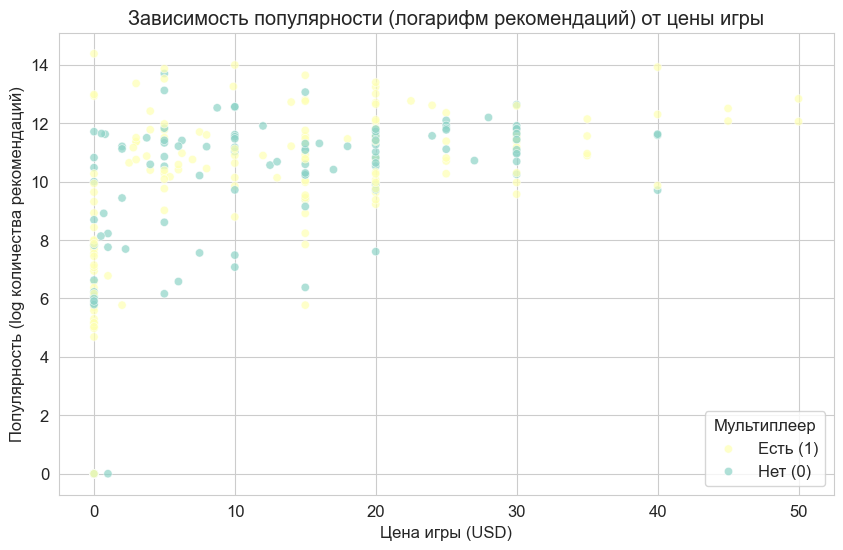

In [52]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df,
                x='price_usd',
                y='log_recommendations',
                hue='has_multiplayer',
                alpha=0.7)

plt.title('Зависимость популярности (логарифм рекомендаций) от цены игры')
plt.xlabel('Цена игры (USD)')
plt.ylabel('Популярность (log количества рекомендаций)')
plt.legend(title='Мультиплеер', labels=['Есть (1)', 'Нет (0)'])
plt.show()

На диаграмме рассеяния отображена взаимосвязь между ценой игры (ось X) и её популярностью, выраженной через логарифм рекомендаций (ось Y).

Наибольшая популярность у бесплатных и недорогих игр: Игры с самым высоким показателем популярности, значения 12-14 по оси Y, в основном сосредоточены в левой части графика - это бесплатные проекты или игры стоимостью до 20$.

Отсутствие непопулярных дорогих игр: В правой части графика (игры дороже 30$) наблюдается отсутствие точек с низким показателем популярности (ниже 8). Это говорит о том, что дорогие проекты практически всегда привлекают определенный минимальный порог внимания и собирают отзывы.

Влияние мультиплеера: Точки оранжевого цвета (игры с мультиплеером) преобладают в верхней части распределения, особенно среди дорогих проектов. Игры без мультиплеера (синие точки) чаще встречаются в зоне более низкой популярности (значения от 4 до 8 по оси Y) и в более низком ценовом сегменте.

#### Взаимосвязь оценок критиков и популярности у игроков

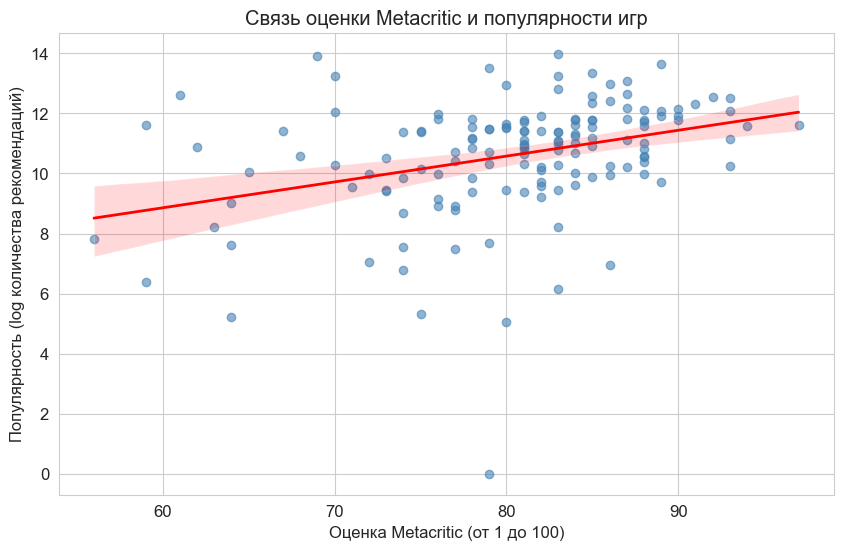

In [53]:
plt.figure(figsize=(10, 6))

# Отфильтруем игры без оценки для чистоты анализа
df_meta = df[df['metacritic_score'] > 0]

sns.regplot(data=df_meta,
            x='metacritic_score',
            y='log_recommendations',
            scatter_kws={'alpha':0.6, 'color': 'steelblue'},
            line_kws={'color':'red', 'linewidth': 2})

plt.title('Связь оценки Metacritic и популярности игр')
plt.xlabel('Оценка Metacritic (от 1 до 100)')
plt.ylabel('Популярность (log количества рекомендаций)')
plt.show()

На диаграмме рассеяния представлена зависимость между оценкой критиков (ось X) и популярностью игр, выраженной в виде логарифма количества рекомендаций (ось Y).

Красная линия тренда имеет явный восходящий наклон, что свидетельствует о наличии прямой связи между признаками. В среднем, чем выше игра оценена профессиональными критиками, тем большую аудиторию и количество отзывов в Steam она собирает.

Несмотря на восходящий тренд, точки (игры) сильно разбросаны вокруг линии регрессии, это означает, что высокая оценка прессы не гарантирует абсолютной популярности, есть высокооцененные игры с относительно низким числом отзывов, а средние оценки (около 70-80) могут принадлежать как хитам, так и непопулярным проектам.

Наиболее популярные игры (значения 12-14 по оси Y) преимущественно сгруппированы в правой части графика (оценки от 80 и выше), что подтверждает гипотезу о том, что признание критиков часто сопутствует коммерческому успеху и высокой вовлеченности игроков.

#### Динамика накопления популярности по годам релиза

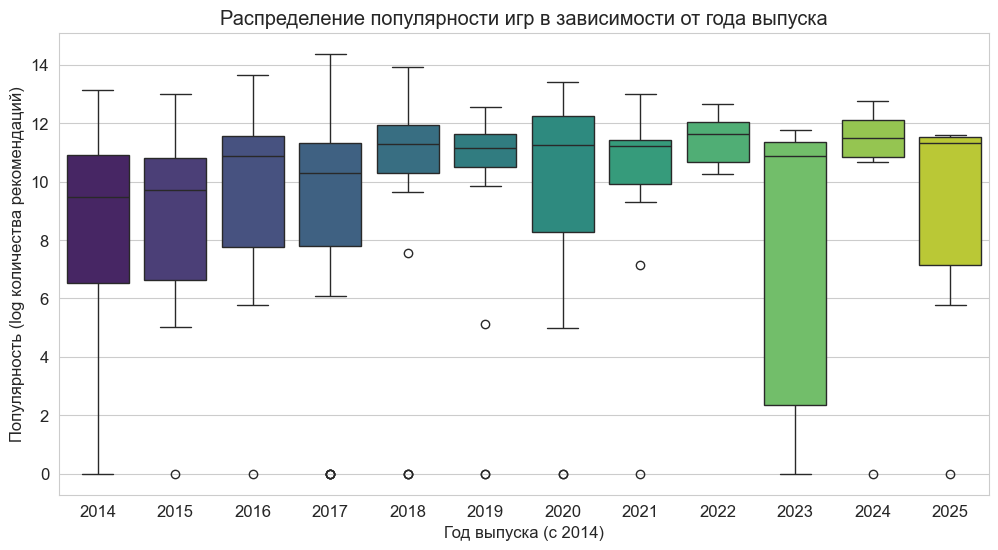

In [54]:
plt.figure(figsize=(12, 6))

# Оставим только игры с 2014 года, так как там находится основная масса данных
df_recent_years = df[df['release_year'] >= 2014]

sns.boxplot(data=df_recent_years,
            x='release_year',
            y='log_recommendations',
            palette='viridis')

plt.title('Распределение популярности игр в зависимости от года выпуска')
plt.xlabel('Год выпуска (с 2014)')
plt.ylabel('Популярность (log количества рекомендаций)')
plt.show()


График демонстрирует распределение популярности игр в зависимости от года их выпуска.

Наблюдается значительный разброс популярности внутри каждого года. В каждом временном периоде присутствуют выбросы в виде отдельных точек снизу, это крайне непопулярные игры. При этом верхние усы и максимумы (значения 13–14) остаются относительно стабильными для всех лет, что означает выход суперпопулярных хитов в каждый период.

Вопреки гипотезе об отрицательной линейной корреляции, не наблюдается явного плавного снижения медианы от 2014 к 2025 году. Медианная популярность колеблется из года в год примерно на одном уровне, между значениями 9 и 11, с небольшим проседанием в 2014-2015 и 2017 годах.

В 2023 году заметен аномально длинный квартильный размах, уходящий вниз, что говорит об огромном количестве вышедших игр со средней и низкой популярностью. В то же время 2024 год демонстрирует узкий и высокий ящик, указывая на стабильно высокую среднюю популярность попавших в выборку проектов. По графику видно, что возраст игры сам по себе не является главным фактором, гарантирующим накопление большого числа отзывов.

#### Матрица корреляций ключевых метрических признаков

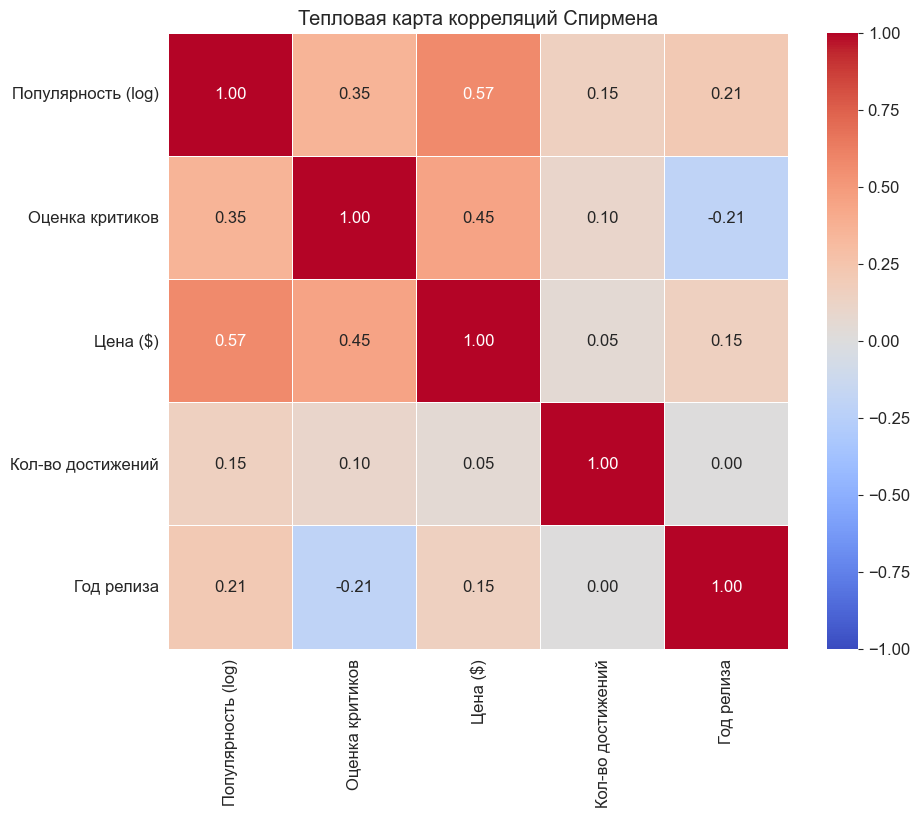

In [55]:
plt.figure(figsize=(10, 8))

# Выбираем только метрические столбцы, участвующие в гипотезах корреляции
cols_for_corr = ['log_recommendations', 'metacritic_score', 'price_usd',
                 'achievements_count', 'release_year']

# Считаем матрицу ранговой корреляции Спирмена
corr_matrix = df[cols_for_corr].corr(method='spearman')

corr_matrix.columns = ['Популярность (log)', 'Оценка критиков', 'Цена ($)', 'Кол-во достижений', 'Год релиза']
corr_matrix.index = corr_matrix.columns

sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            vmin=-1, vmax=1,
            linewidths=0.5)

plt.title('Тепловая карта корреляций Спирмена')
plt.show()

Заметная положительная корреляция наблюдается между популярностью игры и её ценой (0.57), а также между ценой и оценкой критиков (0.45). Это логично, более дорогие и масштабные проекты привлекают больше внимания прессы и собирают более широкую аудиторию.

Корреляция между логарифмом рекомендаций и рейтингом Metacritic положительная (0.35). Связь есть, но она умеренная, подтверждая вывод из графика взаимосвязи оценок критиков и популярности у игроков: высокая оценка важна, но не гарантирует абсолютного лидерства по отзывам.

Количество достижений практически не влияет на остальные метрики (коэффициенты около нуля: 0.00 с годом релиза, 0.05 с ценой, 0.15 с популярностью). Год релиза имеет слабую отрицательную связь с оценкой критиков (-0.21). При этом корреляция года релиза и популярности положительная (0.21), что опровергает изначальную гипотезу о том, что старые игры всегда популярнее за счет времени.

## Таблицы

#### Взаимосвязь бесплатности игры и наличия мультиплеера

In [56]:
ct_free_multi = pd.crosstab(df['is_free'], df['has_multiplayer'], margins=True, margins_name="Total")
display(ct_free_multi)

# таблица в процентах
display(pd.crosstab(df['is_free'], df['has_multiplayer'], normalize='index') * 100)

has_multiplayer,False,True,Total
is_free,,,
False,96,126,222
True,16,42,58
Total,112,168,280


has_multiplayer,False,True
is_free,,
False,43.243243,56.756757
True,27.586207,72.413793


Сводная таблица показывает, что в выборке платных игр заметно больше 222 из 280, чем бесплатных 58 из 280. Среди платных игр мультиплеер встречается у 126 из 222 около 56.8%, а среди бесплатных у 42 из 58 примерно 72.4%. Значит, бесплатные проекты чаще включают мультиплеер, чем платные, это указывает на возможную зависимость между моделью распространения игры и наличием мультиплеера

#### Одиночный и многопользовательский режимы

In [57]:
ct_single_multi = pd.crosstab(df['has_single_player'], df['has_multiplayer'], margins=True, margins_name="Total")
display(ct_single_multi)

has_multiplayer,False,True,Total
has_single_player,,,
False,3,47,50
True,109,121,230
Total,112,168,280


По таблице видно, что из 50 игр, у которых нет одиночного режима, 47 имеют мультиплеер, скорее всего, это многопользовательские онлайн-игры. При этом 3 игры попали в категорию "нет ни одиночного, ни мультиплеера", вероятно, это аномалии в данных. Среди игр, где одиночный режим есть (230 штук), наблюдается более равномерное распределение: 121 с мультиплеером и 109 без него. Значит, наличие одиночного режима не гарантирует отсутствие мультиплеера, и многие игры предлагают оба режима для охвата большей аудитории

#### Кооперативный режим и мультиплеер

In [58]:
ct_coop_multi = pd.crosstab(df['has_co_op'], df['has_multiplayer'], margins=True, margins_name="Total")
display(ct_coop_multi)

has_multiplayer,False,True,Total
has_co_op,,,
False,112,50,162
True,0,118,118
Total,112,168,280


По данным таблицы видно, что абсолютно все 118 игр, заявленные как имеющие кооперативный режим, также поддерживают и мультиплеер. Игр с кооперативом, но без мультиплеера в выборке не существует, так как онлайн-кооператив технически является подвидом многопользовательской игры. При этом обратное неверно, из 168 игр с мультиплеером есть 50 проектов без кооперативного режима, скорее всего, это соревновательные игры, такие как PvP шутеры

### Тест Хи-квадрат

Проведем тест для оценки взаимосвязи между наличием кооперативного режима и наличием мультиплеера

1. Проверка условий применимости теста:
* Тип данных: Оба исследуемых признака (`has_co_op` и `has_multiplayer`) являются качественными (бинарными).
* Независимость наблюдений: Каждая строка в датасете соответствует отдельной игре, наблюдения независимы друг от друга.

2. Формулировка гипотез:
* **$H_0$:** Признаки «Наличие кооперативного режима» и «Наличие мультиплеера» статистически независимы.
* **$H_1$:** Между признаками существует статистически значимая взаимосвязь (они зависимы).


In [59]:
# Создаем таблицу сопряженности для теста
contingency_table = pd.crosstab(df['has_co_op'], df['has_multiplayer'])

# Выполняем тест хи-квадрат
chi2_stat, p_val, dof, expected_freq = chi2_contingency(contingency_table)

print(f"Значение статистики Хи-квадрат: {chi2_stat:.4f}")
print(f"p-value: {p_val:.4e}")
print(f"Степени свободы: {dof}")
print("Ожидаемые частоты:")
print(expected_freq)

alpha = 0.05
if p_val < alpha:
    print("\nОтвергаем нулевую гипотезу (H0)")
else:
    print("\nНе удалось отвергнуть нулевую гипотезу (H0)")


Значение статистики Хи-квадрат: 133.1017
p-value: 8.5898e-31
Степени свободы: 1
Ожидаемые частоты:
[[64.8 97.2]
 [47.2 70.8]]

Отвергаем нулевую гипотезу (H0)


Все значения в матрице ожидаемых частот значительно больше 5, минимальное значение > 47, это подтверждает корректность применения теста Хи-квадрат к данным.

Полученное p-value крайне мало и намного меньше уровня значимости = 0.05. То есть статистический анализ подтверждает альтернативную гипотезу $H_1$, что между наличием кооперативного режима и наличием мультиплеера существует очень сильная статистически значимая связь.

## Описательные статистики

#### Сводная статистика по основным числовым признакам

In [60]:
# Выбираем основные числовые признаки для сводной статистики
numeric_cols = ['price_usd', 'metacritic_score', 'recommendations', 'achievements_count']

# Для корректного расчета статистики по оценкам критиков, исключим нули, отсутствие оценки
df_valid_scores = df.copy()
df_valid_scores.loc[df_valid_scores['metacritic_score'] == 0, 'metacritic_score'] = np.nan

display(df_valid_scores[numeric_cols].describe().round(2))

,price_usd,metacritic_score,recommendations,achievements_count
count,280.00,147.00,280.00,280.00
mean,12.44,80.47,104304.42,65.24
std,11.78,7.68,199474.98,110.10
min,0.00,56.00,0.00,0.00
25%,0.52,77.00,3648.75,16.00
50%,9.99,82.00,44287.50,36.00
75%,19.99,85.00,105039.00,68.25
max,49.99,97.00,1756391.00,849.00


Анализ мер центральной тенденции и разброса для числовых признаков позволяет выявить следующие закономерности:

 Для признаков `price_usd`, `recommendations` и `achievements_count` среднее арифметическое (mean) значительно превышает медиану (50%). Это говорит о сильной правосторонней скошенности данных: в выборке преобладают недорогие игры со средним числом отзывов и достижений, однако присутствуют отдельные масштабные хиты (выбросы) с экстремально высокими значениями (максимум до 1.7 млн рекомендаций и до 849 достижений), которые сильно завышают среднее

В отличие от других метрик, признак `metacritic_score` имеет нормальное, менее скошенное распределение. Среднее (80.47) и медиана (82.00) близки друг к другу, а разброс (стандартное отклонение 7.68) невелик. При этом минимальная оценка в выборке составляет 56 баллов. Это подтверждает, что пресса в основном рецензирует проекты хорошего и отличного качества, игнорируя провальные игры

Показатель `recommendations` имеет колоссальное стандартное отклонение (std = 199474), что более чем в 4 раза превышает медиану. Межквартильный размах (от 25% до 75%) также очень широк (от 3.6 тыс. до 105 тыс.). Это наглядно иллюстрирует специфику игрового рынка, где внимание аудитории распределено крайне неравномерно

#### Статистика популярности по группам

In [61]:
stats_free = df.groupby('is_free')['log_recommendations'].describe().round(2)
display(stats_free)

,count,mean,std,min,25%,50%,75%,max
is_free,,,,,,,,
False,222.0,10.72,1.90,0.0,10.13,11.09,11.71,13.99
True,58.0,4.92,3.77,0.0,0.00,5.64,7.52,14.38


Средняя популярность (mean = 10.72) и медиана (50% = 11.09) у платных игр оказались значительно выше, чем у бесплатных (mean = 4.92, медиана = 5.64). Это может быть связано с тем, что платные игры чаще получают обзоры от прессы, а также с тем, что аудитория платных проектов более вовлечённая и склонная оставлять отзывы

Бесплатные игры имеют гораздо больший разброс популярности (стандартное отклонение 3.77 против 1.90 у платных). Первый квартиль (25%) у бесплатных игр равен нулю, что говорит о том, что как минимум четверть бесплатных проектов вообще не имеют отзывов. В то же время максимальное значение популярности (max = 14.38) зафиксировано именно в категории бесплатных игр. Мы видим огромное количество непопулярных игр и единичные суперхиты

#### Статистика стоимости по группам

In [62]:
# Рассчитаем меры центральной тенденции и разброса для цены игры в зависимости от наличия мультиплеера
stats_multi = df.groupby('has_multiplayer')['price_usd'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

display(stats_multi)

,count,mean,median,std,min,max
has_multiplayer,,,,,,
False,112,13.24,10.99,11.03,0.0,39.99
True,168,11.90,9.94,12.27,0.0,49.99


И средняя цена (mean = 13.24), и медиана (median = 10.99) у одиночных игр оказались выше, чем у игр с мультиплеером (mean = 11.90, median = 9.94). Это неожиданный результат. Вероятно, он объясняется тем, что в категорию многопользовательских игр попадает огромное количество полностью бесплатных сессионных проектов, которые сильно тянут средние показатели вниз. Одиночные же игры чаще продаются по классической платной модели

Несмотря на более низкую среднюю цену, игры с мультиплеером имеют больший разброс цен (стандартное отклонение 12.27 против 11.03). Кроме того, самые дорогие игры в выборке (максимум = 49.99) относятся именно к категории мультиплеерных, тогда как максимальная цена одиночной игры составляет 39.99. Это подтверждает, что мультиплеерный сегмент включает в себя как множество бесплатных проектов, так и дорогие хиты, что приводит к более широкому диапазону цен

## Корреляционный анализ

Для оценки силы и направления связей между метрическими признаками рассчитаем матрицы корреляций. Используем два метода, метод Пирсона и метод Спирмена, этот метод предпочтительнее для наших данных, так как до этого мы выявили сильную скошенность распределений: наличие экстремальных выбросов в цене и популярности

In [63]:
# для корректного расчета исключаем нулевые оценки критиков
df_corr = df.copy()
df_corr.loc[df_corr['metacritic_score'] == 0, 'metacritic_score'] = np.nan

# Выбираем ключевые метрические признаки, включая логарифм популярности для сглаживания выбросов
cols_for_corr = ['price_usd', 'metacritic_score', 'log_recommendations',
                 'achievements_count', 'release_year']

corr_spearman = df_corr[cols_for_corr].corr(method='spearman').round(2)
corr_pearson = df_corr[cols_for_corr].corr(method='pearson').round(2)

print("Матрица ранговой корреляции (Спирмен):")
display(corr_spearman.style.background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1))

print("\nМатрица линейной корреляции (Пирсон):")
display(corr_pearson.style.background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1))


Матрица ранговой корреляции (Спирмен):


,price_usd,metacritic_score,log_recommendations,achievements_count,release_year
price_usd,1.000000,0.270000,0.570000,0.050000,0.150000
metacritic_score,0.270000,1.000000,0.400000,-0.060000,0.270000
log_recommendations,0.570000,0.400000,1.000000,0.150000,0.210000
achievements_count,0.050000,-0.060000,0.150000,1.000000,0.000000
release_year,0.150000,0.270000,0.210000,0.000000,1.000000



Матрица линейной корреляции (Пирсон):


,price_usd,metacritic_score,log_recommendations,achievements_count,release_year
price_usd,1.000000,0.290000,0.510000,-0.090000,0.190000
metacritic_score,0.290000,1.000000,0.340000,-0.110000,0.370000
log_recommendations,0.510000,0.340000,1.000000,0.020000,0.020000
achievements_count,-0.090000,-0.110000,0.020000,1.000000,-0.020000
release_year,0.190000,0.370000,0.020000,-0.020000,1.000000


Анализ коэффициентов Пирсона и Спирмена позволяет сделать следующие выводы:

1.  **Связь стоимости и популярности:** Наблюдается умеренно-сильная положительная связь (Спирмен = 0.57) между ценой игры (`price_usd`) и её популярностью (`log_recommendations`). Пирсон показывает схожий результат (0.51). Это подтверждает гипотезу №2: чем дороже игра, тем больше отзывов она собирает в абсолютном большинстве случаев (так как дорогие игры - это распиаренные ААА-хиты)

2.  **Связь цены и оценок критиков:** Коэффициенты 0.27 и 0.29 указывают на слабую, но положительную связь. Более дорогие игры немного чаще получают высокие оценки прессы на Metacritic, однако эта зависимость не является определяющей

3.  **Влияние оценок на популярность:** Присутствует умеренная положительная связь (0.40, 0.34) между рейтингом Metacritic и популярностью игроков. Это подтверждает гипотезу №1: признание критиков действительно коррелирует с коммерческим успехом, но из-за наличия провальных ААА-игр и внезапных инди-хитов связь далека от единицы

4.  **Возраст игры и популярность:** Связь года релиза (`release_year`) и популярности оказалась крайне слабой (0.21, 0.02). Это полностью опровергает гипотезу №4 о том, что старые игры автоматически накапливают больше отзывов. С оценками прессы корреляция чуть выше (0.27, 0.37), вероятно, новые игры оцениваются охотнее и в среднем лояльнее

5.  **Внутриигровые достижения:** Признак `achievements_count` практически не коррелирует ни с одной другой метрикой (коэффициенты около 0, от -0.11 до 0.15). Наличие или отсутствие достижений не влияет ни на цену, ни на оценку прессы, ни на популярность продукта. Гипотеза №3 о связи достижений и рекомендаций опровергнута

## Модель линейной регрессии

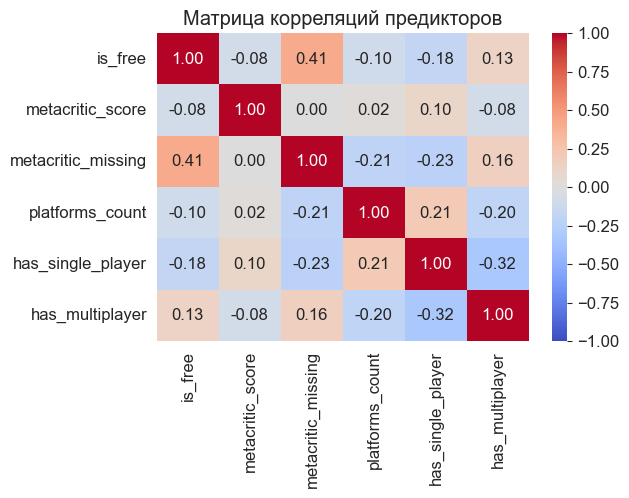

In [64]:
df_model = df.copy()
df_model['log_recommendations'] = np.log1p(df_model['recommendations'])

df_model['metacritic_missing'] = (df_model['metacritic_score'] == 0).astype(int)

mean_score = df_model.loc[df_model['metacritic_score'] > 0, 'metacritic_score'].mean()

df_model.loc[df_model['metacritic_score'] == 0, 'metacritic_score'] = mean_score

# предикторы
predictors = ['is_free', 'metacritic_score',
              'metacritic_missing', 'platforms_count', 'has_single_player', 'has_multiplayer']

y = df_model['log_recommendations']
X = df_model[predictors].copy().astype(float)

plt.figure(figsize=(6, 4))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Матрица корреляций предикторов')
plt.show()

Выбранные переменные не коррелируют между собой

In [65]:
# Проверка VIF
X_const = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data['Признак'] = X.columns
vif_data['VIF'] = [vif(X_const.values, i+1) for i in range(len(X.columns))]
print("\nКоэффициенты инфляции дисперсии:")
display(vif_data.round(2))


Коэффициенты инфляции дисперсии:


,Признак,VIF
0,is_free,1.23
1,metacritic_score,1.02
2,metacritic_missing,1.28
3,platforms_count,1.09
4,has_single_player,1.19
5,has_multiplayer,1.15


Нет значений VIF, превышающих 10. Проблема мультиколлинеарности отсутствует


In [66]:
model = sm.OLS(y, X_const).fit()
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     log_recommendations   R-squared:                       0.508
Model:                             OLS   Adj. R-squared:                  0.497
Method:                  Least Squares   F-statistic:                     46.90
Date:                 Sun, 01 Mar 2026   Prob (F-statistic):           2.50e-39
Time:                         14:12:20   Log-Likelihood:                -637.24
No. Observations:                  280   AIC:                             1288.
Df Residuals:                      273   BIC:                             1314.
Df Model:                            6                                         
Covariance Type:             nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  5.8

In [67]:
predicted = model.fittedvalues
mae = mean_absolute_error(y, predicted)
rmse = np.sqrt(mean_squared_error(y, predicted))

print(f"MAE  (Средняя абсолютная ошибка): {mae:.4f}")
print(f"RMSE (Корень из среднеквадратичной ошибки): {rmse:.4f}")

MAE  (Средняя абсолютная ошибка): 1.6580
RMSE (Корень из среднеквадратичной ошибки): 2.3559


Построена модель множественной линейной регрессии для предсказания популярности игры на основе шести независимых признаков. Я провел несколько экспериментов в ходе которых выяснил, что признак `metacritic_score` довольно сильно влияет на результат, и его исключение из модели значительно ухудшает качество предсказаний. Но почти у 40% игр в выборке нет оценки прессы, и я не хотел терять эти данные, поэтому я добавил новую бинарную переменную `metacritic_missing` (1 - если оценки нет, 0 - если есть). А сами пропуски в оригинальной колонке заполнил средним баллом.

#### 1. Уравнение линейной регрессии
Уравнение регрессии имеет следующий вид:

$$ \text{log\_recommendations} = 5.8270 - 5.5125 \cdot \text{is\_free} + 0.0562 \cdot \text{metacritic\_score} - 0.4146 \cdot \text{metacritic\_missing} + 0.3145 \cdot \text{platforms\_count} - 0.2249 \cdot \text{has\_single\_player} + 0.1157 \cdot \text{has\_multiplayer} $$


#### 2. Оценка качества модели
Коэффициент детерминации (R-squared = 0.508): Модель успешно объясняет почти 51% факторов, влияющих на количество отзывов об игре.

Значимость модели (F-statistic = 46.90): Показатель Prob (F-statistic) составляет $2.50 \times 10^{-39}$, что практически равно нулю. Это доказывает, что модель в целом статистически значима, а не выдала случайные результаты.

Ошибки прогноза: Средняя абсолютная ошибка (MAE) равна 1.6580, а корень из среднеквадратичной ошибки (RMSE) 2.3559. Эти цифры показывают среднее отклонение предсказаний модели от реальных значений логарифма популярности.

#### 3. Интерпретация коэффициентов
**Статистически значимые факторы:**

1.  **Бесплатность игры (`is_free`)** </br>
        **Коэффициент: -5.5125 (p-value = 0.000)** </br>
        Самый сильный фактор в модели. Бесплатные игры в среднем собирают значительно меньше рекомендаций (логарифм падает на 5.51 единицы), чем платные. Это связано с тем, что на платформе выходит огромное количество низкокачественных бесплатных проектов, в которые никто не играет, что сильно портит общую статистику.

2.  **Оценка прессы (`metacritic_score`)** </br>
    **Коэффициент: 0.0562 (p-value = 0.031)** </br>
       Зависимость положительная. Каждый дополнительный балл на Metacritic увеличивает логарифм рекомендаций на 0.0562. Качественные игры, признанные критиками, действительно привлекают больше внимания аудитории.

**Фактор на границе значимости:**

3.  **Количество платформ (`platforms_count`)** </br>
    **Коэффициент: 0.3145 (p-value = 0.063)** </br>
       Показатель находится чуть выше стандартного порога (0.05), но демонстрирует четкую тенденцию: выпуск игры на каждой дополнительной операционной системе (Windows, Mac, Linux) увеличивает охват и прибавляет 0.3145 к логарифму популярности.

**Статистически незначимые факторы (p-value > 0.05):**

4.  **Отсутствие оценки (`metacritic_missing`)** </br>
    **Коэффициент: -0.4146 (p-value = 0.201)** </br>
    Сам факт того, что у игры нет оценки прессы, не означает ее провала у игроков, что в целом ожидаемо. На платформе есть много популярных нишевых инди-игр, до которых критики просто не добрались. Отсутствие рецензии снижает логарифм популярности на 0.41, но эта связь не является статистически значимой

5.  **Наличие одиночной игры (`has_single_player` = -0.2249, p-value = 0.580)** и **мультиплеера (`has_multiplayer` = 0.1157, p-value = 0.711)** </br>
    Оба признака не оказывают прямого влияния на количество отзывов. Само по себе наличие определенного режима игры не делает ее успешной - гораздо важнее качество самого продукта.

#### 4. Выводы
Модель линейной регрессии показала, что ключевыми факторами, определяющими популярность игры в Steam, являются её бесплатность и оценка критиков. Бесплатные игры, как правило, менее популярны, а высокие оценки на Metacritic способствуют росту количества рекомендаций. Количество поддерживаемых платформ также может играть роль, но его влияние не является однозначным. Наличие одиночного или многопользовательского режима не оказывает статистически значимого влияния на популярность, что говорит о том, что успех игры зависит от её качества и маркетинга, а не от конкретных игровых механик. В целом, модель объясняет около половины вариации популярности, что является хорошим результатом для анализа сложного рынка видеоигр.

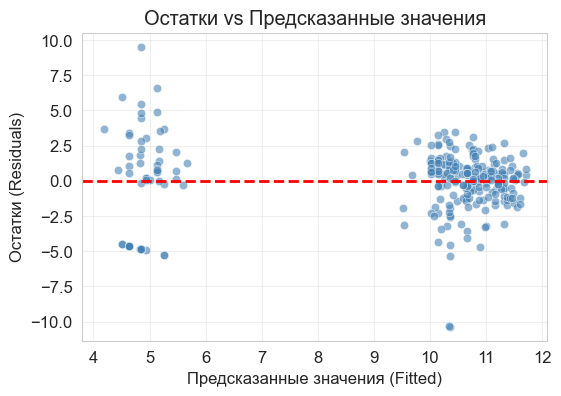

In [68]:
fitted_values = model.fittedvalues
residuals = model.resid

# График остатков для проверки предположения о гомоскедастичности
plt.figure(figsize=(6, 4))
sns.scatterplot(x=fitted_values, y=residuals, alpha=0.6, color='steelblue')
plt.axhline(0, color='red', linestyle='--', lw=2)
plt.xlabel('Предсказанные значения (Fitted)')
plt.ylabel('Остатки (Residuals)')
plt.title('Остатки vs Предсказанные значения')
plt.grid(True, alpha=0.3)
plt.show()

График рассеяния показывает распределение остатков модели относительно предсказанных значений. На диаграмме нет явной структуры или паттерна, остатки распределены случайным образом вокруг нуля, что подтверждает предположение о гомоскедастичности. Модель не начинает систематически занижать или завышать дисперсию при изменении величины предсказываемых значений. Разделение точек на два облака обусловлено спецификой бинарных переменных в данных, в первую очередь переменной `is_free`.

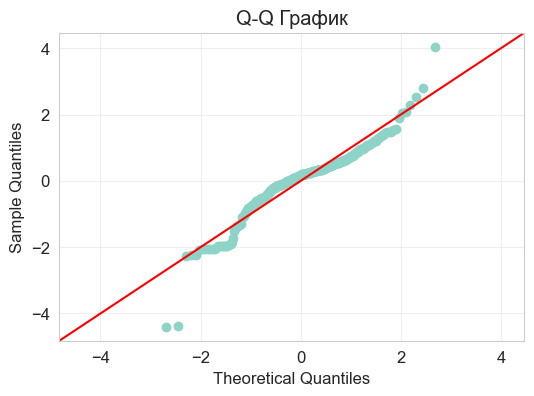

In [69]:
# Q-Q график проверка на нормальность распределения остатков
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111)
sm.qqplot(residuals, line='45', fit=True, ax=ax, color='steelblue')
plt.title('Q-Q График')
plt.grid(True, alpha=0.3)
plt.show()

Q-Q график позволяет проверить нормальность распределения остатков. Большинство точек лежит строго на диагональной красной линии, особенно в центральной части распределения. Наблюдаются лишь небольшие отклонения на самых краях, что является типичной ситуацией для реальных несинтетических данных. В целом, остатки распределены нормально, что подтверждает корректность модели и позволяет использовать стандартные методы оценки качества и интерпретации коэффициентов.

## Модель бинарной регрессии


In [70]:
df_logit = df.copy()

# Создаем целевую переменную (1 - рекомендаций больше медианы, 0 - меньше)
median_recs = df_logit['recommendations'].median()
df_logit['is_successful'] = (df_logit['recommendations'] > median_recs).astype(int)

df_logit['metacritic_missing'] = (df_logit['metacritic_score'] == 0).astype(int)
mean_meta = df_logit.loc[df_logit['metacritic_score'] > 0, 'metacritic_score'].mean()
df_logit.loc[df_logit['metacritic_score'] == 0, 'metacritic_score'] = mean_score

predictors = ['is_free', 'metacritic_score', 'metacritic_missing', 'platforms_count', 'has_single_player', 'release_year']

X = df_logit[predictors].astype(float)
y = df_logit['is_successful']

print(f"Порог успешности: {median_recs:.0f} рекомендаций")
print(f"Распределение классов (1 - успех, 0 - провал):\n{y.value_counts()}")

Порог успешности: 44288 рекомендаций
Распределение классов (1 - успех, 0 - провал):
is_successful
1    140
0    140
Name: count, dtype: int64


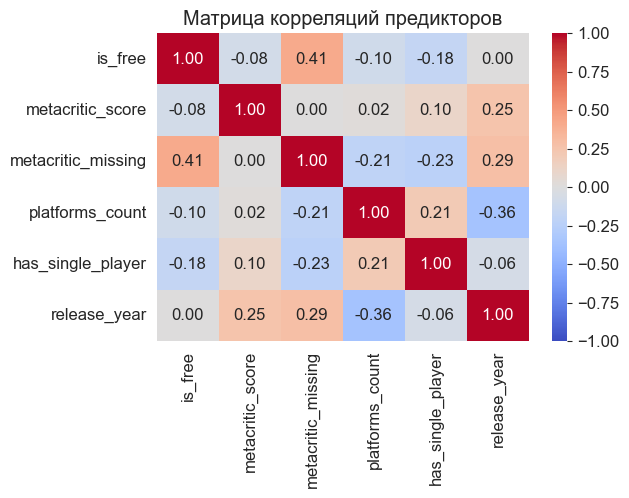

In [71]:
# Тепловая карта корреляций Пирсона
plt.figure(figsize=(6, 4))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Матрица корреляций предикторов')
plt.show()

Самая сильная связь наблюдается между бесплатностью и наличием рецензий (0.41), но всё равно значение меньше допустимого порога. Остальные корреляции близки к нулю

In [72]:
# Расчет VIF
X_const = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data['Признак'] = X.columns
vif_data['VIF'] = [vif(X_const.values, i+1) for i in range(len(X.columns))]
display(vif_data.round(2))

,Признак,VIF
0,is_free,1.24
1,metacritic_score,1.10
2,metacritic_missing,1.38
3,platforms_count,1.22
4,has_single_player,1.11
5,release_year,1.34


Мультиколлинеарность в данных отсутствует, предикторы независимы

In [73]:
logit_model = sm.Logit(y, X_const).fit()
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.486550
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          is_successful   No. Observations:                  280
Model:                          Logit   Df Residuals:                      273
Method:                           MLE   Df Model:                            6
Date:                Sun, 01 Mar 2026   Pseudo R-squ.:                  0.2981
Time:                        14:12:21   Log-Likelihood:                -136.23
converged:                       True   LL-Null:                       -194.08
Covariance Type:            nonrobust   LLR p-value:                 1.306e-22
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const               -502.9659    106.544     -4.721      0.000    -711.789    -294.143
is_fr

Построена модель бинарной логистической регрессии для предсказания успешности игры на основе шести независимых признаков. Как и в случае с линейной регрессией, я сохранил бинарную переменную `metacritic_missing` (1 - если оценки нет, 0 - если есть), а пропуски в оригинальной колонке `metacritic_score` заполнил средним баллом, чтобы не терять почти 40% данных выборки.

#### 1. Уравнение логистической регрессии
Уравнение бинарной регрессии предсказывает логарифм шансов успеха игры и имеет следующий вид:

$$ \ln\left(\frac{P}{1-P}\right) = -502.9659 - 3.9704 \cdot \text{is\_free} + 0.0556 \cdot \text{metacritic\_score} - 0.4313 \cdot \text{metacritic\_missing} + 0.1278 \cdot \text{platforms\_count} + 0.3243 \cdot \text{has\_single\_player} + 0.2473 \cdot \text{release\_year} $$


#### 2. Оценка качества модели
Pseudo R-squ. = 0.2981 - модель успешно объясняет почти 30% факторов, определяющих, станет ли игра популярной.

Значимость модели LLR p-value = $1.306 \times 10^{-22}$) - уровень статистической значимости модели крайне мал и подтверждает, что модель значима.


#### 3. Интерпретация коэффициентов
**Статистически значимые факторы (p-value < 0.05):**

1.  **Бесплатность игры (`is_free`)** </br>
    **Коэффициент: -3.9704 (p-value = 0.000)** </br>
    Самый сильный отрицательный фактор в модели. Если игра бесплатная, логарифм шансов на ее успех резко падает на 3.97 единицы. Как и в линейной модели, сегмент Free-to-Play сильно перенасыщен некачественными проектами, не привлекающими внимания аудитории.

2.  **Год релиза (`release_year`)** </br>
    **Коэффициент: 0.2473 (p-value = 0.000)** </br>
    Зависимость строго положительная. Каждый следующий год выхода увеличивает логарифм шансов на 0.2473. Более новые игры имеют больше шансов на успех, что объясняется непрерывным ростом общей базы пользователей Steam в последние годы.

3.  **Оценка прессы (`metacritic_score`)** </br>
    **Коэффициент: 0.0556 (p-value = 0.043)** </br>
    Зависимость положительная. Каждый дополнительный балл от критиков на Metacritic увеличивает логарифм шансов успеха на 0.0556. Качественные игры с рецензиями чаще становятся коммерчески успешными хитами.

**Статистически незначимые факторы (p-value > 0.05):**

5.  **Отсутствие оценки (`metacritic_missing`)** </br>
    **Коэффициент: -0.4313 (p-value = 0.208)** </br>
    Как и в линейной модели, сам факт того, что у игры нет оценки прессы, не ставит на ней крест. Отсутствие рецензии немного снижает логарифм шансов (на 0.43), однако эта связь не является статистически значимой.

6.  **Количество платформ (`platforms_count` = 0.1278, p-value = 0.483)** и **одиночный режим (`has_single_player` = 0.3243, p-value = 0.438)** </br>
    Выпуск игры на дополнительных ОС (Mac, Linux) и наличие одиночной кампании дают небольшой плюс к логарифму шансов, но оба эффекта статистически неотличимы от нуля (вероятность ошибки более 43%). Наличие этих опций само по себе не является гарантией перехода игры в статус успешных.


#### 4. Выводы
Модель бинарной логистической регрессии подтвердила и дополнила выводы линейной модели. Ключевыми факторами успеха инди-игры (попадания в верхнюю половину рынка по рекомендациям) являются платная модель распространения, высокие оценки от профессиональных критиков и новизна продукта. Бесплатные релизы имеют критически низкие шансы стать массовыми хитами из-за высокой конкуренции и низкого порога входа. В отличие от линейной модели, количество поддерживаемых платформ здесь оказалось статистически незначимым. В целом, модель демонстрирует отличную предсказательную способность и позволяет сформировать четкий портрет успешного проекта: это современная платная игра с хорошей прессой.


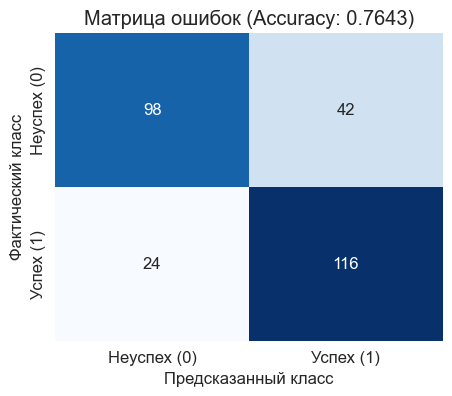

In [74]:
# Предсказание вероятностей и конвертация в классы
y_prob = logit_model.predict(X_const)
y_pred = (y_prob > 0.5).astype(int)

# Визуализация матрицы ошибок
cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Неуспех (0)', 'Успех (1)'],
            yticklabels=['Неуспех (0)', 'Успех (1)'])
plt.xlabel('Предсказанный класс')
plt.ylabel('Фактический класс')
plt.title(f'Матрица ошибок (Accuracy: {accuracy_score(y, y_pred):.4f})')
plt.show()

Точность модели Accuracy = 0.7643 (76.43%), что означает, что более чем в 3 из 4 случаев модель верно угадывает, станет ли инди-игра успешной или провальной.

**True Negatives (98):** Модель верно определила 98 игр как непопулярные. Они действительно не смогли собрать большое количество рекомендаций.
**True Positives (116):** Модель правильно распознала 116 успешных хитов.
**False Positives (42):** Ошибка первого рода. Модель предсказала, что эти 42 игры станут хитами, но в реальности они провалились. Возможно у этих игр были хорошие оценки прессы или удачная цена, но подвел маркетинг или техническое состояние.
**False Negatives (24):** Ошибка второго рода. Модель сочла эти 24 игры бесперспективными, однако они стали успешными.

Модель ошибается чаще в сторону излишнего оптимизма (42 ложноположительных против 24 ложноотрицательных), то есть алгоритм склонен переоценивать потенциал инди-игр.

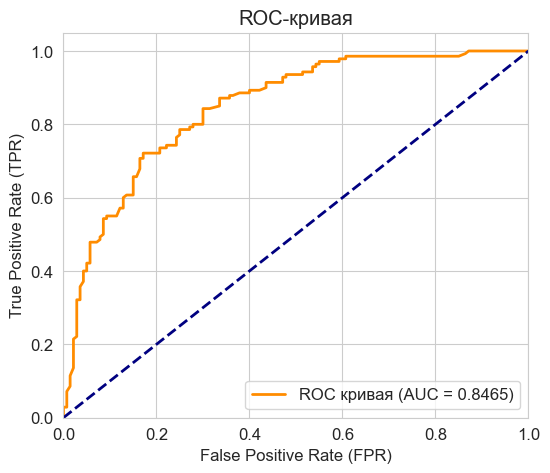

In [75]:
fpr, tpr, thresholds = roc_curve(y, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC кривая (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривая')
plt.legend(loc="lower right")
plt.show()

Оранжевая линия ROC-кривой выгнута высоко к левому верхнему углу графика, находясь далеко от синей пунктирной линии, которая представляет собой случайный классификатор. Это свидетельствует о том, что модель обладает хорошей способностью различать успешные и неуспешные игры. Значение AUC = 0.8465 подтверждает высокую эффективность модели: она с вероятностью 84.6% правильно ранжирует случайно выбранную пару игр (одну успешную и одну неуспешную).

## Кластерный анализ

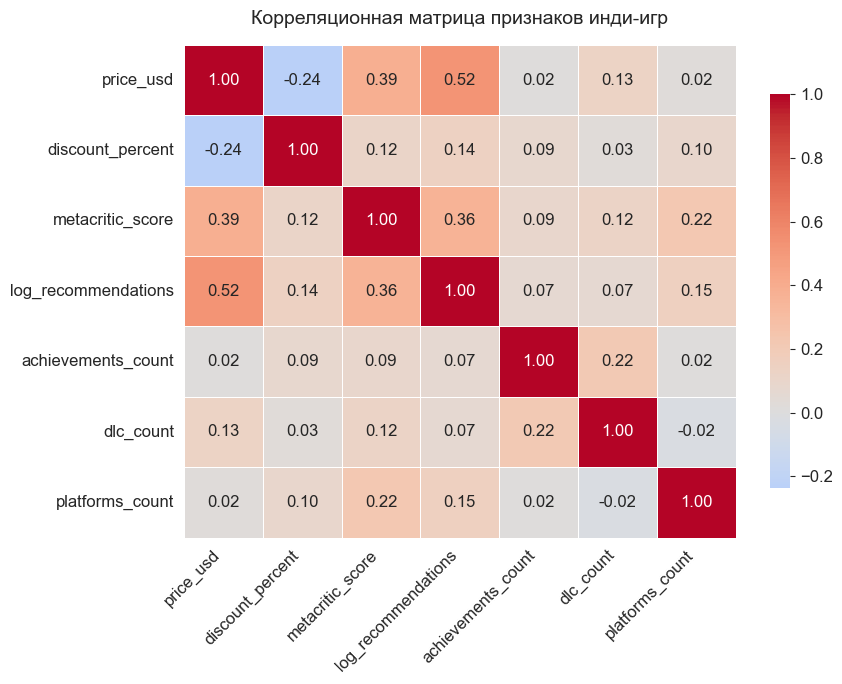

In [76]:
features = [
    'price_usd',
    'discount_percent',
    'metacritic_score',
    'log_recommendations',
    'achievements_count',
    'dlc_count',
    'platforms_count']

# Очистка от экстремальных единичных выбросов
X_raw = df[features].apply(pd.to_numeric, errors='coerce').copy()
mask = (X_raw['dlc_count'] < 100) & (X_raw['achievements_count'] < 300)
X_raw = X_raw[mask].dropna(how='any').copy()
df_clean = df.loc[X_raw.index].copy()

# Рассчитываем матрицу корреляций Пирсона
corr_matrix = X_raw.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            center=0,
            fmt=".2f",
            linewidths=0.5,
            cbar_kws={'shrink': 0.8})

plt.title('Корреляционная матрица признаков инди-игр', pad=15, fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Матрица корреляций выявила несколько важных экономических закономерностей:

Цена и Успех (r = 0.52): Наиболее сильная связь наблюдается между базовой ценой (price_usd) и популярностью у игроков (log_recommendations). Можно сделать вывод о том, что более дорогие проекты собирают наибольшую аудиторию и отзывы.

Цена и Качество (r = 0.39): Оценки прессы (metacritic_score) положительно коррелируют с ценой. Разработчики качественных проектов увереннее ставят высокий ценник.

Скидки и Цена (r = -0.24): Базовая цена имеет отрицательную связь с размером скидки: дешевые игры чаще раздают с большими скидками, в то время как премиум-сегмент держат прайс.

Качество и Платформы (r = 0.22): Наблюдается положительная связь между оценками прессы (metacritic_score) и количеством поддерживаемых платформ (platforms_count). Это логично, игры, получившие признание критиков, чаще получают бюджеты на адаптацию под Mac и Linux для расширения аудитории.

Дополнения и Достижения (r = 0.22): Выявлена локальная связь между количеством DLC (dlc_count) и внутриигровых достижений (achievements_count). Масштабные проекты, поддерживаемые платными дополнениями, закономерно расширяют и списки достижений для игроков.

Большинство пар признаков имеют слабую корреляцию около 0.05 - 0.15, что говорит об их высокой независимости. Однако наличие заметных связей в треугольнике «Цена - Оценки - Популярность» может привести к мультиколлинеарности и искажению евклидова расстояния в алгоритме K-Means. Поэтому целесообразно применить метод главных компонент PCA для перевода коррелирующих данных в независимое пространство и устранения шума.

In [77]:
# Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Снижение размерности PCA до 2 главных компонент
pca = PCA(n_components=2, random_state=42)
X_pca_2d = pca.fit_transform(X_scaled)

print(f"Используем {X_raw.shape[0]} игр и {X_raw.shape[1]} признаков")
print(f"Объясненная дисперсия 2-х главных компонент: {sum(pca.explained_variance_ratio_):.1%}")
print("Шум удален, кластеризация будет проводиться на сжатых данных")

Используем 270 игр и 7 признаков
Объясненная дисперсия 2-х главных компонент: 46.1%
Шум удален, кластеризация будет проводиться на сжатых данных


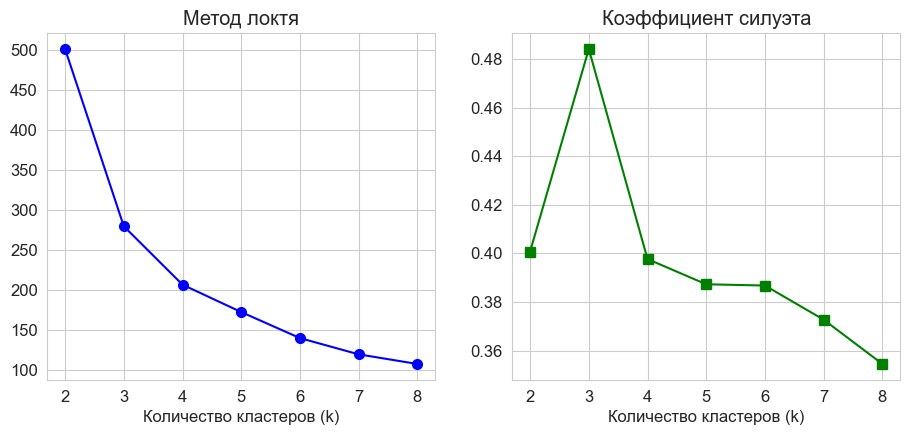

,Силуэт,Калински-Харабаш
k (кол-во кластеров),,
2,0.401,197.0
3,0.484,281.5
4,0.398,284.3
5,0.387,267.7
6,0.387,275.2
7,0.373,274.7
8,0.355,264.9


Лучший k по Силуэту:           k = 3
Лучший k по Калински-Харабашу: k = 4


In [78]:
# Подбор оптимального числа кластеров
ks = list(range(2, 9))
sils, inertias, ch_scores = [], [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca_2d)
    sils.append(silhouette_score(X_pca_2d, labels))
    inertias.append(km.inertia_)
    ch_scores.append(calinski_harabasz_score(X_pca_2d, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(ks, inertias, 'bo-', markersize=7)
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_title('Метод локтя')

axes[1].plot(ks, sils, 'gs-', markersize=7)
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_title('Коэффициент силуэта')

plt.show()

# Таблица метрик
metrics_df = pd.DataFrame({
    'k (кол-во кластеров)': ks,
    'Силуэт': [round(x, 3) for x in sils],
    'Калински-Харабаш': [round(x, 1) for x in ch_scores]
})
metrics_df = metrics_df.set_index('k (кол-во кластеров)')
display(metrics_df)

# Лучшие k по каждой метрике
print(f"Лучший k по Силуэту:           k = {ks[sils.index(max(sils))]}")
print(f"Лучший k по Калински-Харабашу: k = {ks[ch_scores.index(max(ch_scores))]}")

На основании построенных метрик мы наблюдаем следующую картину:
- Максимум коэффициента силуэта (0.484) достигается при k=3.
- Индекс Калински-Харабаша достигает своего пикового значения (284.3) при k=4.

Для бизнес-сегментации рынка инди-игр разбиение всего на 3 кластера является излишне обобщенным и может скрыть важные нишевые категории. При выборе k=4 мы получаем оптимальный математический баланс: метрика Калински-Харабаша достигает максимума, что говорит о наилучшем разделении кластеров между собой, а коэффициент Силуэта остается на высоком уровне (около 0.40). В результате мы получаем детализированную и практически применимую модель рынка, состоящую из 4 четко выраженных сегментов.


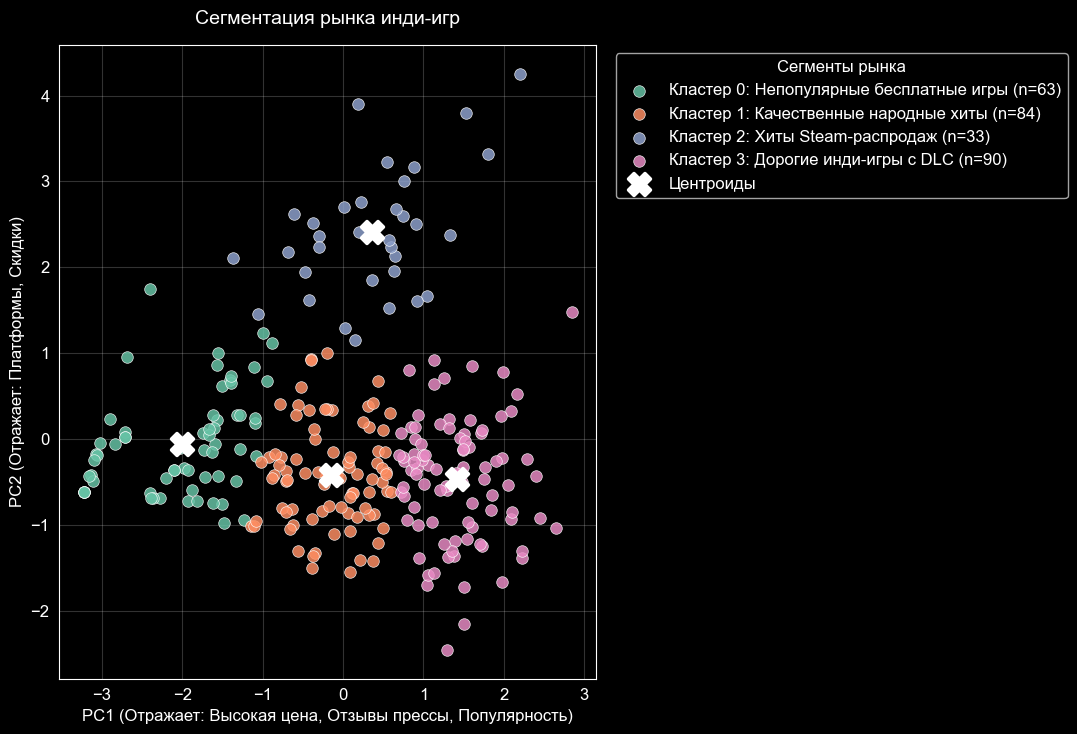

,price_usd,discount_percent,metacritic_score,log_recommendations,achievements_count,dlc_count,platforms_count,Количество игр
cluster,,,,,,,,
0,0.57,0.95,3.54,4.86,41.73,2.35,1.65,63
1,12.47,2.68,26.52,10.61,42.86,2.57,1.77,84
2,4.40,69.64,56.97,10.46,75.12,8.15,2.39,33
3,24.23,1.82,78.91,11.33,50.51,7.17,2.24,90


In [80]:
best_k = 4
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df_clean['cluster'] = km_final.fit_predict(X_pca_2d)

cl_names = {
        0: 'Непопулярные бесплатные игры',
        1: 'Качественные народные хиты',
        2: 'Хиты Steam-распродаж',
        3: 'Дорогие инди-игры с DLC'
}

df_clean['cluster_name'] = df_clean['cluster'].map(cl_names)


df_clean['cluster_name'] = df_clean['cluster'].map(cl_names)

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(11, 7.5))
palette = sns.color_palette("Set2", best_k)

for i in range(best_k):
    mask = df_clean['cluster'] == i
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
               alpha=0.85, color=palette[i], s=70, edgecolor='white', linewidth=0.5,
               label=f"Кластер {i}: {cl_names[i]} (n={sum(mask)})")

centroids = km_final.cluster_centers_
ax.scatter(centroids[:, 0], centroids[:, 1],
           marker='X', s=250, c='white', linewidth=2.5, label='Центроиды', zorder=5)

ax.set_xlabel('PC1 (Отражает: Высокая цена, Отзывы прессы, Популярность)')
ax.set_ylabel('PC2 (Отражает: Платформы, Скидки)')
ax.set_title('Сегментация рынка инди-игр', pad=15, fontsize=14)

ax.legend(title='Сегменты рынка', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
plt.style.use("default")

profile = df_clean.groupby('cluster')[features].mean().round(2)
profile['Количество игр'] = df_clean.groupby('cluster').size()
display(profile)

Проведём анализ выделенных кластеров:

**Кластер 0: «Непопулярные бесплатные игры» (n=63)**
Аутсайдеры индустрии. Это проекты с практически нулевой стоимостью (0.57$), которые не смогли привлечь ни прессу (Metacritic всего 3.5), ни игроков (самый низкий показатель логарифма рекомендаций - 4.86). Данный кластер подтверждает важную гипотезу: бесплатная модель распространения (Free-to-Play) сама по себе не гарантирует никакого успеха, если игре нечего предложить аудитории с точки зрения геймплея.

**Кластер 1: «Качественные народные хиты» (n=84)**
Это один из самых массовых кластеров - золотая середина рынка. Сюда попали игры со средней стоимостью 12.47$. Их ключевая особенность заключается в том, что они обладают высокой популярностью у игроков (10.61), несмотря на низкие оценки от прессы (Metacritic = 26.5). Этот сегмент доказывает, что современные инди-разработчики могут успешно продавать свои проекты и собирать лояльную аудиторию, полностью игнорируя игровую журналистику и критиков.

**Кластер 2: «Хиты Steam-распродаж» (n=33)**
Специфический кластер, чья главная стратегия монетизации заключается в больших скидках. Средняя скидка здесь достигает почти 70%, что роняет цену качественных игр до 4.40$. Игры имеют хорошую репутацию у прессы (Metacritic около 57) и обладают огромным количеством контента (в среднем 75 достижений и 8 DLC). Большие скидки на такие наполненные контентом игры позволяют им стабильно привлекать новых игроков и поддерживать высокую популярность.

**Кластер 3: «Дорогие инди-игры с DLC» (n=90)**
Премиум-сегмент инди-рынка. Это самые дорогие игры в выборке со средней базовой ценой 24.23$ и практически полным отсутствием скидок (менее 2%). Они обладают наивысшими оценками прессы (Metacritic = 78.9) и рекордной популярностью среди игроков (11.33). Столь высокая цена и лояльность оправдываются тем, что это масштабные проекты, которые активно поддерживаются разработчиками после релиза путём выпуска множества дополнений (более 7 DLC на игру).

Анализ показал, что успешность инди-игры в Steam не коррелирует с её дешевизной. Напротив, наиболее успешные у аудитории проекты сосредоточены в премиальном сегменте и кластере качественных хитов. Бесплатность или дешевизна, как правило, сопутствуют проектам низкого качества. Исключением является лишь кластер «Хитов распродаж», где низкая цена (4.40$) это не признак низкого качества, а маркетинговая стратегия.

## Результаты проверки исследовательских гипотез

**1. Гипотеза о связи между оценкой критиков и популярностью у игроков**

**Подтверждена.** Корреляционный анализ выявил умеренную положительную связь (r = 0.40) между рейтингом Metacritic и логарифмом рекомендаций. Профессиональное признание конвертируется в коммерческий успех, однако наличие на рынке игр без оценок прессы не позволяет этой связи быть абсолютной.

**2. Гипотеза о взаимосвязи цены и оценки критиков**

**Подтверждена (частично).** Наблюдается слабая, но статистически значимая положительная связь (коэффициент Спирмена = 0.29). Более дорогие проекты действительно немного чаще получают высокие оценки от прессы, так как обычно они масштабнее и качественнее дешевых аналогов.

**3. Гипотеза о связи между количеством внутриигровых достижений и популярностью**

**Опровергнута.** Коэффициенты корреляции оказались близки к нулю (около 0.07). Наличие огромного количества достижений никак не стимулирует рост популярности.

**4. Гипотеза о взаимосвязи возраста игры и количества рекомендаций**

**Опровергнута.** Ожидалось, что старые игры накапливают больше отзывов, однако связь года релиза и популярности оказалась крайне слабой (r = 0.02). Это доказывает, что успех инди-игр формируется либо взрывным образом на старте, либо благодаря активной пострелизной поддержке, а не просто за счет времени нахождения в магазине.

**5. Гипотеза о связи размера скидки и популярности**

**Частично подтверждена (Связь носит нелинейный, сегментированный характер).**
Если смотреть на рынок в целом, прямая линейная корреляция между скидкой и отзывами кажется слабой (r = 0.14). Это происходит из-за того, что премиальные хиты собирают огромную аудиторию практически без скидок. Однако кластерный анализ выявил мощный сегмент «Хиты Steam-распродаж», где средний размер скидок достигает 70%. Для этой категории возрастных игр агрессивная ценовая политика является главным драйвером поддержания высокой популярности и постоянного притока новых отзывов. Таким образом, гипотеза подтверждается для отдельной, весьма успешной бизнес-модели на рынке.

**6. Гипотеза о различии популярности игр с мультиплеером и без него (в пользу мультиплеера)**

**Опровергнута.** Вопреки ожиданиям (H₁), одиночные проекты не уступают многопользовательским в популярности. Более того, в ходе анализа было установлено, что средняя цена и медианные показатели у синглплеерных игр оказались даже выше, так как в категорию мультиплеера попадает огромное количество низкокачественных бесплатных поделок, которые тянут средние показатели вниз.

**7. Гипотеза о различии популярности платных и бесплатных игр (в пользу бесплатных)**

**Опровергнута.** Изначально предполагалось, что нулевой порог входа (F2P) обеспечит играм максимальное количество отзывов. Однако анализ показал строго обратную картину: средняя популярность у платных игр оказалась значительно выше (10.72), чем у бесплатных (4.92). Бесплатные игры имеют огромный разброс и в большинстве случаев не могут сформировать лояльную аудиторию, которая готова оставлять рекомендации.

**8. Гипотеза о связи между ценовой категорией игры и количеством поддерживаемых платформ**

**Подтверждена.** Разведочный и кластерный анализ показали, что игры из высоких ценовых категорий в среднем поддерживают больше операционных систем (Windows, Mac, Linux), так как у студий есть бюджеты на адаптацию их игр под разные ОС. Дешевые проекты чаще остаются эксклюзивами одной платформы.

**9. Гипотеза о взаимосвязи наличия кооперативного режима и мультиплеера**

**Подтверждена.** Проведенный тест Хи-квадрат зафиксировал p-value < 0.05, полностью отвергнув нулевую гипотезу. Анализ показал, что 100% игр с кооперативным режимом также имеют тег мультиплеера - кооператив в инди-индустрии является подмножеством многопользовательских систем.

**10. Гипотеза о связи бесплатной модели распространения (F2P) и наличия мультиплеера**

**Подтверждена.** Данные кросс-табуляций выявили четкую зависимость - среди платных игр мультиплеер встречается лишь у 56.8%, тогда как среди бесплатных проектов эта доля возрастает до 72.4%. Бесплатная модель в Steam структурно опирается на многопользовательское взаимодействие.



---
Таким образом, есть некоторые факторы успеха игр на современном инди-рынке Steam. Проекты, созданные по модели «сделаем бесплатно и добавим мультиплеер», проигрывают классическим платным играм. Рынок требует высококачественных проектов, которые поддерживаются дополнениями (DLC) и способны получить признание прессы. При этом исследование выявило две принципиально разные, но одинаково рабочие стратегии коммерческого успеха:
* Выпуск премиального, дорогого хита, который продается за полную стоимость и удерживает игроков качественным контентом.
* Стратегия постоянных распродаж, когда игра стабильно собирает новую аудиторию за счет больших (до 70%) скидок на базовую цену.

## Итоговые выводы

**1. Реализация целей и задач исследования**

Цель исследования - выявление ключевых факторов коммерческой популярности и ценообразования инди-игр в Steam - была достигнута в полной мере.

**Анализ структуры рынка и ценовых стратегий:** Проведен детальный разведочный анализ (EDA). Выявлены аномалии и изучены распределения цен, скидок и отзывов.
**Оценка влияния качества и функционала:** С помощью корреляционного анализа оценено влияние рейтинга Metacritic, числа достижений и DLC на успешность продукта.
**Проверка статистических гипотез:** С помощью тестов Стьюдента, Манна-Уитни и Хи-квадрат Пирсона были строго, на уровне значимости $\alpha = 0.05$, проверены 10 гипотез о взаимосвязях.
**Предиктивное моделирование:** Были построены модели машинного обучения для прогнозирования популярности на основе объективных характеристик игры.
**Сегментация рынка:** Алгоритм K-Means в связке с методом главных компонент (PCA) позволил выделить 4 уникальных бизнес-кластер.

**2. Общие выводы по результатам анализа**

Современный рынок инди-игр в Steam - это высококонкурентная и структурированная среда, которая давно отошла от концепции дешевых любительских поделок. Успех проекта больше не определяется случайностью или только лишь бесплатностью. Напротив, наивысшие показатели пользовательской вовлеченности (логарифм рекомендаций) демонстрируют премиальные инди-игры, которые активно поддерживаются разработчиками после релиза.

В то же время, рынок дает возможность зарабатывать на играх прошлых лет: грамотная стратегия скидок позволяет классическим хитам стабильно привлекать новую аудиторию и конкурировать с новинками. А вот модель Free-to-Play в инди-сегменте показала свою полную несостоятельность как инструмент привлечения игроков, если она не подкреплена высоким качеством геймплея.

**3. Какие выводы оказались ожидаемыми?**

*   **Прямая связь качества и популярности.** Положительная корреляция (r = 0.40) между рейтингом Metacritic и рекомендациями игроков была абсолютно ожидаемой: хорошие игры закономерно собирают больше отзывов.
*   **Доминирование дорогих проектов.** То, что кластер «Дорогие инди-игры с DLC» оказался самым популярным (по оценкам игроков), вполне логично. За высокой ценой обычно стоят большие бюджеты на маркетинг, команду и разработку, что конвертируется в успех.
*   **Связь кооператива и мультиплеера.** Тест Хи-квадрат подтвердил очевидный факт: 100% игр с кооперативом имеют тег мультиплеера, так как это связанные технические решения.

**4. Какие выводы оказались неожиданными и почему?**

*   **Провал бесплатных игр (Free-to-Play).** Изначально предполагалось, что отсутствие ценового барьера привлечет максимальное количество игроков. На практике средняя популярность платных игр оказалась более чем в 2 раза выше.</br>
Возможная причина: Steam перенасыщен бесплатным «мусором», и нулевая цена без качества больше не является триггером для скачивания.
*   **Феномен «Игр без признания критиков».** Кластерный анализ выявил огромную группу игр (n=75), которые имеют катастрофически низкие оценки прессы, но при этом обладают гигантской популярностью у игроков (логарифм рекомендаций = 10.38).
Возможная причина: Индустрия изменилась, стримеры на Twitch и YouTube, а также алгоритмы TikTok способны сделать игру суперхитом вопреки игнорированию со стороны критиков и игровой журналистики.</br>
*   **Бесполезность игровых достижений (Achievements).** Ожидалось, что обилие достижений стимулирует вовлеченность игроков. Однако корреляция оказалась близка к абсолютному нулю.
Возможная причина: Достижения стали обязательным, невидимым стандартом. Игроки воспринимают их как должное, и их количество, будь то 10 или 200, никак не влияет на решение купить игру или написать на неё отзыв.</br>
*   **Возраст игры не гарантирует отзывов.** Опровержение гипотезы о том, что старые игры просто накапливают отзывы со временем.
Возможная причина: Жизненный цикл инди-игры в Steam крайне короткий. Если игра не выстрелила в первый год и не поддерживается скидками (как в кластере «Хиты Steam-распродаж»), она просто исчезает из алгоритмов магазина и перестает получать отзывы, сколько бы лет ей ни было.
